Restaurant ratings EDA

1. Select businesses tagged Restaurants or Food.
2. Reserve a test set.
3. Clean attributes, hours, and locations.
4. Compare the two tags and their overlap.
5. Check missing data and geographic coverage.
6. Explore ratings and business features.
7. Save the data for modeling.

1. Load the data

Keep all Restaurants-tagged businesses, including closed ones. Compare Food separately and count shared businesses once. Check IDs and numeric ranges.

In [1]:
from pathlib import Path
import ast
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline

# Locate the project from either its root or the notebooks directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/source_manifest.json').exists())
RAW = ROOT / 'data/01_raw'
OUT = ROOT / 'reports/eda'
PROCESSED = ROOT / 'data/02_processed'
OUT.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 6021
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
BLUE, ORANGE = '#276A86', '#B56A3D'

def finish(fig, filename):
    fig.text(0.01, 0.005, 'Source: local Yelp Open Dataset; development restaurants only; snapshot downloaded 2026-10-21.',
             fontsize=8, color='dimgray')
    fig.tight_layout(rect=[0, 0.08, 1, 1])
    fig.savefig(OUT / filename, dpi=160, bbox_inches='tight')
    plt.show()

def takeaway(text):
    display(Markdown('Takeaway: ' + text))

business = pd.read_json(RAW / 'yelp_academic_dataset_business.json', lines=True,
                        dtype={'business_id': str, 'postal_code': str})
category_lists = business['categories'].fillna('').map(
    lambda value: [x.strip() for x in value.split(',') if x.strip()])
restaurant_mask = category_lists.map(lambda values: 'Restaurants' in values)
food_mask = category_lists.map(lambda values: 'Food' in values)
restaurants = business.loc[restaurant_mask].copy()
restaurants['category_count'] = category_lists.loc[restaurant_mask].map(len)
inventory = pd.DataFrame([
    ['Business rows', len(business)], ['Restaurant rows', len(restaurants)],
    ['Businesses missing categories', int(business.categories.isna().sum())],
], columns=['Measure', 'Count'])
display(inventory)
print('Kernel:', sys.executable)
print('Python:', platform.python_version(), 'pandas:', pd.__version__, 'numpy:', np.__version__)

,Measure,Count
0,Business rows,150346
1,Restaurant rows,52268
2,Businesses missing categories,103


Kernel: /Users/johnschroter/miniforge3/bin/python
Python: 3.10.8 pandas: 1.5.3 numpy: 1.23.5


In [2]:
# Structural checks use all source rows. Target-driven exploration starts AFTER the split.
quality = pd.Series({
    'business IDs missing': int(business.business_id.isna().sum()),
    'duplicate business IDs': int(business.business_id.duplicated().sum()),
    'restaurant ratings missing or outside 1–5': int((~restaurants.stars.between(1, 5)).sum()),
    'restaurant ratings not on half-star increments': int((restaurants.stars.mul(2) % 1 != 0).sum()),
    'restaurant review counts invalid': int(((restaurants.review_count < 0) | restaurants.review_count.isna()).sum()),
    'restaurant latitude invalid': int((~restaurants.latitude.between(-90, 90)).sum()),
    'restaurant longitude invalid': int((~restaurants.longitude.between(-180, 180)).sum()),
    'restaurant open status invalid': int((~restaurants.is_open.isin([0, 1])).sum()),
}, name='Rows flagged')
display(quality.to_frame())
assert quality.sum() == 0, 'Inspect structural problems before proceeding; do not silently drop them.'
takeaway(f'The source contains {len(business):,} businesses, of which {len(restaurants):,} carry the Restaurants category. '
         'Our unit of analysis is one restaurant, so each restaurant receives one row and equal weight in this EDA.')

,Rows flagged
business IDs missing,0
duplicate business IDs,0
restaurant ratings missing or outside 1–5,0
restaurant ratings not on half-star increments,0
restaurant review counts invalid,0
restaurant latitude invalid,0
restaurant longitude invalid,0
restaurant open status invalid,0


Takeaway: The source contains 150,346 businesses, of which 52,268 carry the Restaurants category. Our unit of analysis is one restaurant, so each restaurant receives one row and equal weight in this EDA.

2. Split the data

Reserve about 20% using business IDs. Explore ratings using only the development set.

In [3]:
def split_score(business_id):
    digest = hashlib.sha256(f'{SEED}:{business_id}'.encode()).digest()
    return int.from_bytes(digest[:8], 'big') / 2**64

restaurants['split'] = restaurants.business_id.map(
    lambda key: 'holdout' if split_score(key) < 0.20 else 'development')
development_ids = set(restaurants.loc[restaurants.split.eq('development'), 'business_id'])
holdout_ids = set(restaurants.loc[restaurants.split.eq('holdout'), 'business_id'])
assert development_ids.isdisjoint(holdout_ids)
assert len(development_ids) + len(holdout_ids) == len(restaurants)
print(f'Development: {len(development_ids):,} restaurants; holdout: {len(holdout_ids):,} restaurants.')

Development: 41,802 restaurants; holdout: 10,466 restaurants.


3. Clean the data

Standardize attributes and city names. Handle overnight hours and leave unclear schedules missing. Missing information does not mean No.

In [4]:
def decode_attribute(value):
    if value is None or (isinstance(value, str) and value.strip() in ['', 'None', 'null']):
        return None
    if isinstance(value, str):
        try:
            return ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return value.strip()
    return value

def attribute_value(attributes, key):
    return decode_attribute(attributes.get(key)) if isinstance(attributes, dict) else None

# Clean the union once so all comparisons use identical preparation.
comparison_businesses = business.loc[restaurant_mask | food_mask].copy()
comparison_businesses['category_count'] = category_lists.loc[comparison_businesses.index].map(len)
comparison_businesses['split'] = comparison_businesses.business_id.map(
    lambda key: 'holdout' if split_score(key) < 0.20 else 'development')
assert comparison_businesses.business_id.is_unique
assert comparison_businesses.stars.between(1, 5).all()
assert comparison_businesses.stars.mul(2).mod(1).eq(0).all()
assert comparison_businesses.review_count.ge(0).all()
assert comparison_businesses.latitude.between(-90, 90).all()
assert comparison_businesses.longitude.between(-180, 180).all()
assert comparison_businesses.is_open.isin([0, 1]).all()
feature_frame = comparison_businesses.drop(columns=['attributes', 'hours', 'address', 'name', 'categories']).copy()
attribute_keys = {
    'price_range': 'RestaurantsPriceRange2', 'takeout': 'RestaurantsTakeOut',
    'delivery': 'RestaurantsDelivery', 'outdoor_seating': 'OutdoorSeating',
    'reservations': 'RestaurantsReservations', 'alcohol': 'Alcohol',
    'wifi': 'WiFi', 'noise_level': 'NoiseLevel',
}
binary_attributes = ['takeout', 'delivery', 'outdoor_seating', 'reservations']
for new_name, raw_key in attribute_keys.items():
    values = comparison_businesses.attributes.map(lambda attrs: attribute_value(attrs, raw_key))
    if new_name in binary_attributes:
        feature_frame[new_name] = values.map(
            lambda value: 'Yes' if value is True else ('No' if value is False else np.nan))
    elif new_name == 'price_range':
        # Missing numeric entries may make pandas represent integers as floats.
        price_numeric = pd.to_numeric(values, errors='coerce')
        feature_frame[new_name] = price_numeric.map(
            lambda value: str(int(value)) if value in [1, 2, 3, 4] else np.nan)
    else:
        feature_frame[new_name] = values.map(lambda value: str(value) if value is not None else np.nan)

def time_minutes(value):
    hour, minute = map(int, value.split(':'))
    if not (0 <= hour <= 24 and 0 <= minute < 60 and (hour != 24 or minute == 0)):
        raise ValueError('Invalid clock time')
    return hour * 60 + minute

def summarize_hours(hours):
    if not isinstance(hours, dict) or not hours:
        return pd.Series([np.nan, np.nan, False, False])
    total = 0.0
    ambiguous = malformed = False
    for interval in hours.values():
        try:
            start, end = interval.split('-')
            duration = (time_minutes(end) - time_minutes(start)) % 1440
            if duration == 0:
                ambiguous = True
            total += duration / 60
        except (AttributeError, ValueError, TypeError):
            malformed = True
    return pd.Series([len(hours), np.nan if ambiguous or malformed else total, ambiguous, malformed])

feature_frame[['listed_days', 'weekly_listed_hours', 'hours_ambiguous', 'hours_malformed']] = (
    comparison_businesses.hours.apply(summarize_hours))
# Normalize one explicit city-name variation, preserving the source city column.
city_clean = feature_frame.city.str.strip().copy()
st_louis = feature_frame.state.eq('MO') & city_clean.isin(['Saint Louis', 'St Louis', 'St. Louis'])
city_clean.loc[st_louis] = 'St. Louis'
city_label_changes = int(city_clean.ne(feature_frame.city).sum())
feature_frame['city_state'] = city_clean + ', ' + feature_frame.state.str.strip()
feature_frame['log1p_review_count'] = np.log1p(feature_frame.review_count)
# Keep the existing restaurant exports/schema stable; add tags to the comparison data.
combined_features = feature_frame.copy()
combined_features['is_restaurant_tag'] = restaurant_mask.loc[combined_features.index]
combined_features['is_food_tag'] = food_mask.loc[combined_features.index]
combined_features['category_group'] = np.select(
    [combined_features.is_restaurant_tag & combined_features.is_food_tag,
     combined_features.is_restaurant_tag], ['Both tags', 'Restaurants only'], default='Food only')
assert combined_features.weekly_listed_hours.dropna().between(0, 168).all()
feature_frame = feature_frame.loc[restaurant_mask.loc[feature_frame.index]].copy()
city_label_changes = int(city_clean.loc[feature_frame.index].ne(feature_frame.city).sum())
dev = feature_frame.loc[feature_frame.split.eq('development')].copy()
numeric_features = ['latitude', 'longitude', 'category_count', 'listed_days', 'weekly_listed_hours']
categorical_features = ['state', 'city_state', *attribute_keys.keys()]
assert len(numeric_features) >= 4 and len(categorical_features) >= 4
assert dev[list(attribute_keys)].notna().any().all(), 'A decoded attribute unexpectedly became entirely missing'
assert set(dev.price_range.dropna()) == {'1', '2', '3', '4'}
assert dev.weekly_listed_hours.dropna().between(0, 168).all()
dictionary = pd.DataFrame({
    'Variable': ['stars', *numeric_features, *categorical_features, 'review_count', 'is_open'],
    'Role': ['Target'] + ['Candidate numeric predictor'] * len(numeric_features)
            + ['Candidate categorical predictor'] * len(categorical_features)
            + ['Descriptive / availability-dependent', 'Descriptive / status at snapshot'],
})
display(dictionary)
display(dev[numeric_features + ['stars', 'review_count']].describe().T.round(2))
print(f'City-label normalization: {city_label_changes:,} rows changed; Saint Louis/St Louis/St. Louis in MO share one display label. Raw city preserved.')

,Variable,Role
0,stars,Target
1,latitude,Candidate numeric predictor
2,longitude,Candidate numeric predictor
3,category_count,Candidate numeric predictor
4,listed_days,Candidate numeric predictor
5,weekly_listed_hours,Candidate numeric predictor
6,state,Candidate categorical predictor
7,city_state,Candidate categorical predictor
8,price_range,Candidate categorical predictor
9,takeout,Candidate categorical predictor


,count,mean,std,min,25%,50%,75%,max
latitude,41802.0,36.99,6.01,27.58,32.21,39.48,39.96,53.65
longitude,41802.0,-87.94,13.87,-120.08,-90.24,-86.05,-75.35,-74.66
category_count,41802.0,4.66,2.32,1.00,3.00,4.00,6.00,36.00
listed_days,35994.0,6.55,0.85,1.00,6.00,7.00,7.00,7.00
weekly_listed_hours,28267.0,69.41,25.48,0.25,53.00,71.00,84.00,167.88
stars,41802.0,3.51,0.83,1.00,3.00,3.50,4.00,5.00
review_count,41802.0,87.80,193.11,5.00,13.00,33.00,89.00,7568.00


City-label normalization: 1,950 rows changed; Saint Louis/St Louis/St. Louis in MO share one display label. Raw city preserved.


3a. Compare Restaurants and Food

Compare each tag, their overlap, and their combined group. Use development data for ratings and missingness. Adding Food broadens the study beyond restaurants.

,all_businesses,development_businesses,mean_stars_dev,median_reviews_dev,under_20_reviews_pct_dev
group,,,,,
Restaurants (includes both),52268,41802,3.51,33.0,34.96
Food (includes both),27781,22187,3.67,22.0,46.18
Both tags,15472,12354,3.67,33.0,34.98
Food only (added by union),12309,9833,3.68,14.0,60.26
Restaurants or Food (union),64577,51635,3.55,28.0,39.78


Mutually exclusive groups — development data:


,development_businesses,mean_stars,median_reviews
category_group,,,
Restaurants only,29448,3.45,34.0
Both tags,12354,3.67,33.0
Food only,9833,3.68,14.0


Missing attributes by group (% of development businesses):


,price_range,takeout,delivery,reservations,weekly_listed_hours
category_group,,,,,
Restaurants only,15.1,8.8,12.9,14.3,31.4
Both tags,14.5,9.0,15.9,26.3,34.7
Food only,18.3,28.7,53.1,96.4,39.2


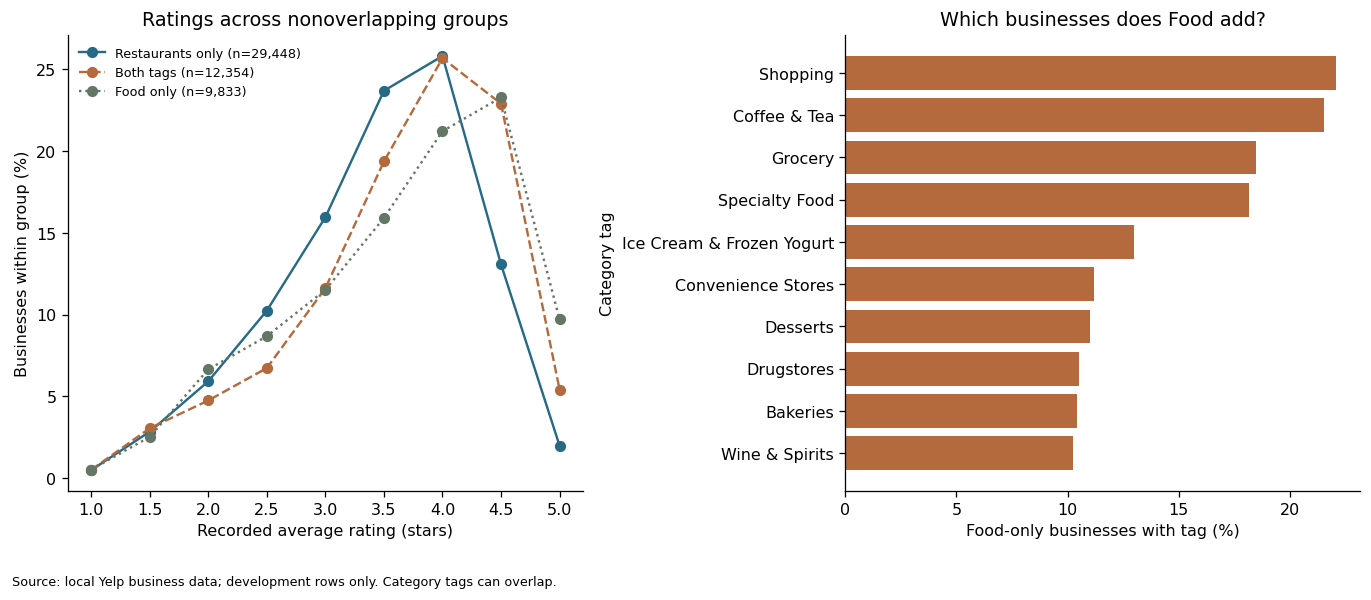

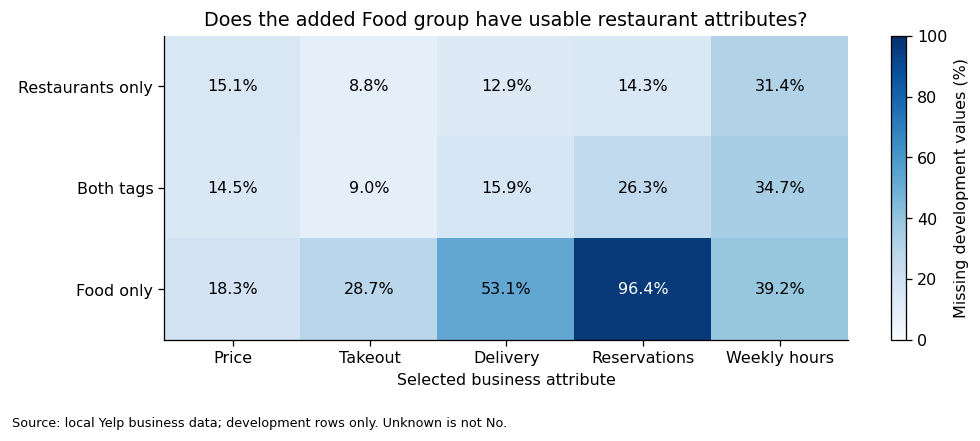

Takeaway: Food adds 12,309 businesses beyond the 52,268 Restaurants-tagged businesses, giving 64,577 unique businesses. Food-only development tags include Shopping, Coffee & Tea, Grocery, Specialty Food, Ice Cream & Frozen Yogurt. Combining is valid for a broader food-business question, but changes the population and does not prove better restaurant prediction.

Takeaway: Food-only delivery is missing for 53.1% of development rows, versus 12.9% for Restaurants only. Keep category-group indicators in a combined model and compare group-specific validation errors before adopting it; some restaurant attributes may not apply to the added businesses.

1633

In [5]:
# AI-assisted scope comparison: exact tags, shared cleaning and stable ID splits.
combined_dev = combined_features.loc[combined_features['split'].eq('development')].copy()
cohort_masks = {
    'Restaurants (includes both)': combined_features.is_restaurant_tag,
    'Food (includes both)': combined_features.is_food_tag,
    'Both tags': combined_features.is_restaurant_tag & combined_features.is_food_tag,
    'Food only (added by union)': ~combined_features.is_restaurant_tag & combined_features.is_food_tag,
    'Restaurants or Food (union)': pd.Series(True, index=combined_features.index),
}
cohort_rows = []
for label, mask in cohort_masks.items():
    all_rows = combined_features.loc[mask]
    development = all_rows.loc[all_rows['split'].eq('development')]
    cohort_rows.append({'group': label, 'all_businesses': len(all_rows),
        'development_businesses': len(development), 'mean_stars_dev': development.stars.mean(),
        'median_reviews_dev': development.review_count.median(),
        'under_20_reviews_pct_dev': development.review_count.lt(20).mean() * 100})
cohort_comparison = pd.DataFrame(cohort_rows).set_index('group')
assert len(combined_features) == int(restaurant_mask.sum() + food_mask.sum() - (restaurant_mask & food_mask).sum())
assert combined_features.business_id.is_unique
cohort_comparison.to_csv(OUT / 'restaurant_food_cohorts.csv')
display(cohort_comparison.round(2))

group_order = ['Restaurants only', 'Both tags', 'Food only']
exclusive_summary = combined_dev.groupby('category_group').agg(
    development_businesses=('business_id', 'size'), mean_stars=('stars', 'mean'),
    median_reviews=('review_count', 'median')).reindex(group_order)
missing_fields = ['price_range', 'takeout', 'delivery', 'reservations', 'weekly_listed_hours']
missing_by_group = combined_dev.groupby('category_group')[missing_fields].agg(
    lambda values: values.isna().mean() * 100).reindex(group_order)
exclusive_summary.to_csv(OUT / 'restaurant_food_exclusive_groups.csv')
missing_by_group.to_csv(OUT / 'restaurant_food_missingness.csv')
print('Mutually exclusive groups — development data:')
display(exclusive_summary.round(2))
print('Missing attributes by group (% of development businesses):')
display(missing_by_group.round(1))

# Food-only category labels identify the extra business mix without using holdout data.
food_only_dev = combined_dev.loc[combined_dev.category_group.eq('Food only')]
extra_categories = category_lists.loc[food_only_dev.index].explode()
extra_categories = extra_categories.loc[~extra_categories.isin(['Food', 'Restaurants'])]
food_only_tags = extra_categories.value_counts().rename_axis('category').to_frame('development_businesses')
food_only_tags['pct_food_only_development'] = food_only_tags.development_businesses / len(food_only_dev) * 100
food_only_tags.to_csv(OUT / 'food_only_category_mix.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
styles = [(BLUE, '-'), (ORANGE, '--'), ('#647766', ':')]
for group, (color, style) in zip(group_order, styles):
    values = combined_dev.loc[combined_dev.category_group.eq(group), 'stars']
    percentages = values.value_counts(normalize=True).reindex(np.arange(1, 5.01, .5), fill_value=0) * 100
    axes[0].plot(percentages.index, percentages.values, marker='o', linestyle=style,
                 color=color, label=f'{group} (n={len(values):,})')
axes[0].set(title='Ratings across nonoverlapping groups', xlabel='Recorded average rating (stars)',
            ylabel='Businesses within group (%)', xticks=np.arange(1, 5.01, .5))
axes[0].legend(frameon=False, fontsize=8)
shown = food_only_tags.head(10).iloc[::-1]
axes[1].barh(shown.index, shown.pct_food_only_development, color=ORANGE)
axes[1].set(title='Which businesses does Food add?', xlabel='Food-only businesses with tag (%)', ylabel='Category tag')
fig.text(.01, .01, 'Source: local Yelp business data; development rows only. Category tags can overlap.', fontsize=8)
fig.tight_layout(rect=[0, .06, 1, 1])
fig.savefig(OUT / '09_restaurants_food_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.8))
heat = ax.imshow(missing_by_group.to_numpy(), vmin=0, vmax=100, cmap='Blues', aspect='auto')
ax.set(xticks=range(len(missing_fields)), xticklabels=['Price', 'Takeout', 'Delivery', 'Reservations', 'Weekly hours'],
       yticks=range(3), yticklabels=group_order, xlabel='Selected business attribute',
       title='Does the added Food group have usable restaurant attributes?')
for row in range(3):
    for col in range(len(missing_fields)):
        value = missing_by_group.iloc[row, col]
        ax.text(col, row, f'{value:.1f}%', ha='center', va='center', color='white' if value > 55 else 'black')
fig.colorbar(heat, ax=ax, label='Missing development values (%)')
fig.text(.01, .01, 'Source: local Yelp business data; development rows only. Unknown is not No.', fontsize=8)
fig.tight_layout(rect=[0, .06, 1, 1])
fig.savefig(OUT / '10_restaurants_food_missingness.png', dpi=160, bbox_inches='tight')
plt.show()

added = int((food_mask & ~restaurant_mask).sum())
takeaway(f'Food adds {added:,} businesses beyond the {len(restaurants):,} Restaurants-tagged businesses, '
         f'giving {len(combined_features):,} unique businesses. Food-only development tags include '
         + ', '.join(food_only_tags.head(5).index) + '. Combining is valid for a broader food-business question, '
         'but changes the population and does not prove better restaurant prediction.')
takeaway(f'Food-only delivery is missing for {missing_by_group.loc["Food only", "delivery"]:.1f}% of development rows, '
         f'versus {missing_by_group.loc["Restaurants only", "delivery"]:.1f}% for Restaurants only. '
         'Keep category-group indicators in a combined model and compare group-specific validation errors before adopting it; '
         'some restaurant attributes may not apply to the added businesses.')
cohort_summary = {'all_restaurants': int(restaurant_mask.sum()), 'all_food': int(food_mask.sum()),
    'both': int((restaurant_mask & food_mask).sum()), 'food_only': added, 'union': len(combined_features),
    'development_comparison': cohort_comparison.reset_index().to_dict(orient='records'),
    'recommendation': 'Keep all Restaurants tags for the restaurant question. The union is usable for a broader food-business question, with deduplication and group-aware validation; predictive benefit is not tested here.'}
(OUT / 'restaurant_food_summary.json').write_text(json.dumps(cohort_summary, indent=2, allow_nan=False))


4. Check missing values

Count missing values and inspect unusual observations. Keep valid extremes, such as high review counts.

,missing_n,missing_pct,observed_unique
noise_level,13973,33.43,4
weekly_listed_hours,13535,32.38,444
wifi,11584,27.71,3
alcohol,9839,23.54,3
outdoor_seating,8281,19.81,2
reservations,7459,17.84,2
price_range,6235,14.92,4
listed_days,5808,13.89,7
delivery,5773,13.81,2
takeout,3713,8.88,2


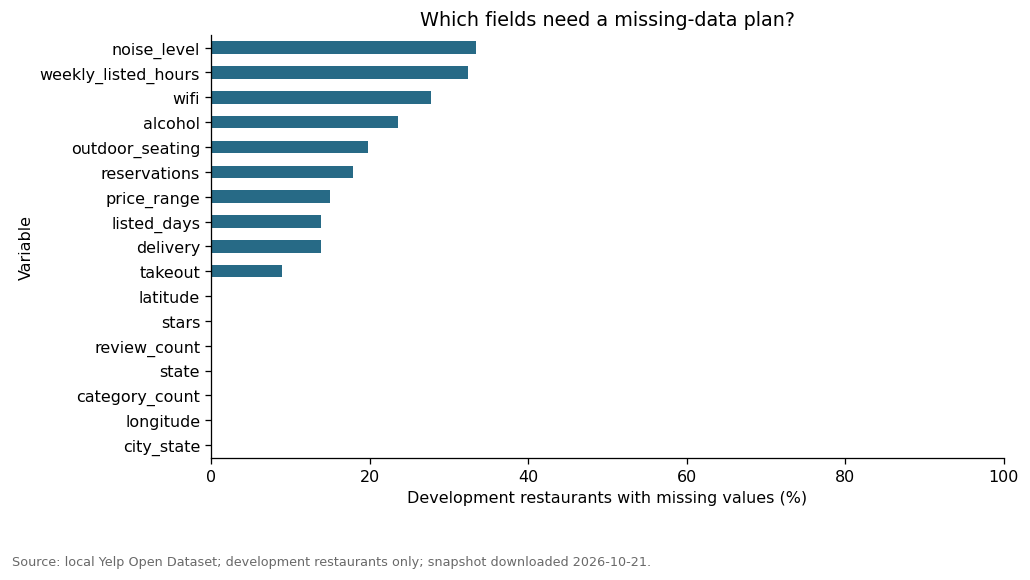

,Development restaurants
ambiguous hour schedules,7727
malformed hour schedules,0
complete across all candidate predictors,14833


Takeaway: The most incomplete selected field is noise_level, missing for 33.4% of development restaurants. Unknown attributes must remain distinct from No. Missingness patterns alone do not establish why values are missing.

In [6]:
audit_columns = ['stars', 'review_count', *numeric_features, *categorical_features]
missingness = pd.DataFrame({
    'missing_n': dev[audit_columns].isna().sum(),
    'missing_pct': dev[audit_columns].isna().mean() * 100,
    'observed_unique': dev[audit_columns].nunique(),
}).sort_values('missing_pct', ascending=False)
display(missingness.round(2))
fig, ax = plt.subplots(figsize=(9, 5))
missingness.missing_pct.sort_values().plot.barh(ax=ax, color=BLUE)
ax.set(xlabel='Development restaurants with missing values (%)', ylabel='Variable',
       title='Which fields need a missing-data plan?', xlim=(0, 100))
finish(fig, '01_missingness.png')
display(pd.Series({
    'ambiguous hour schedules': int(dev.hours_ambiguous.sum()),
    'malformed hour schedules': int(dev.hours_malformed.sum()),
    'complete across all candidate predictors': int(dev[numeric_features + categorical_features].notna().all(axis=1).sum()),
}, name='Development restaurants').to_frame())
takeaway(f'The most incomplete selected field is {missingness.index[0]}, missing for {missingness.iloc[0].missing_pct:.1f}% of development restaurants. '
         'Unknown attributes must remain distinct from No. Missingness patterns alone do not establish why values are missing.')

Keep incomplete rows where possible. Fill missing values using training data only.

5. Check locations

Count businesses by state, including states with no records. Coverage is limited; Alberta (AB) is in Canada.

33 of 50 US states have zero restaurant rows:
AL, AK, AR, CT, GA, IA, KS, KY, ME, MD, MA, MI, MN, MS, NE, NH, NM, NY, ND, OH, OK, OR, RI, SC, SD, TX, UT, VT, VA, WA, WV, WI, WY
US states with at least one row:


,restaurant_rows
PA,12641
FL,8731
TN,4352
MO,4247
IN,4150
LA,3640
NJ,3341
AZ,2671
NV,1673
ID,1302


Codes outside the 50 US states (inspect separately):


,restaurant_rows
AB,2410
XMS,1


A code outside the US list may be a Canadian province (AB) or an anomalous code (XMS); do not infer a country from this test alone.
Regions with fewer than 30 restaurant rows, retained but unsuitable for regional comparisons:


,restaurant_rows
NC,1
CO,1
HI,1
MT,1
XMS,1


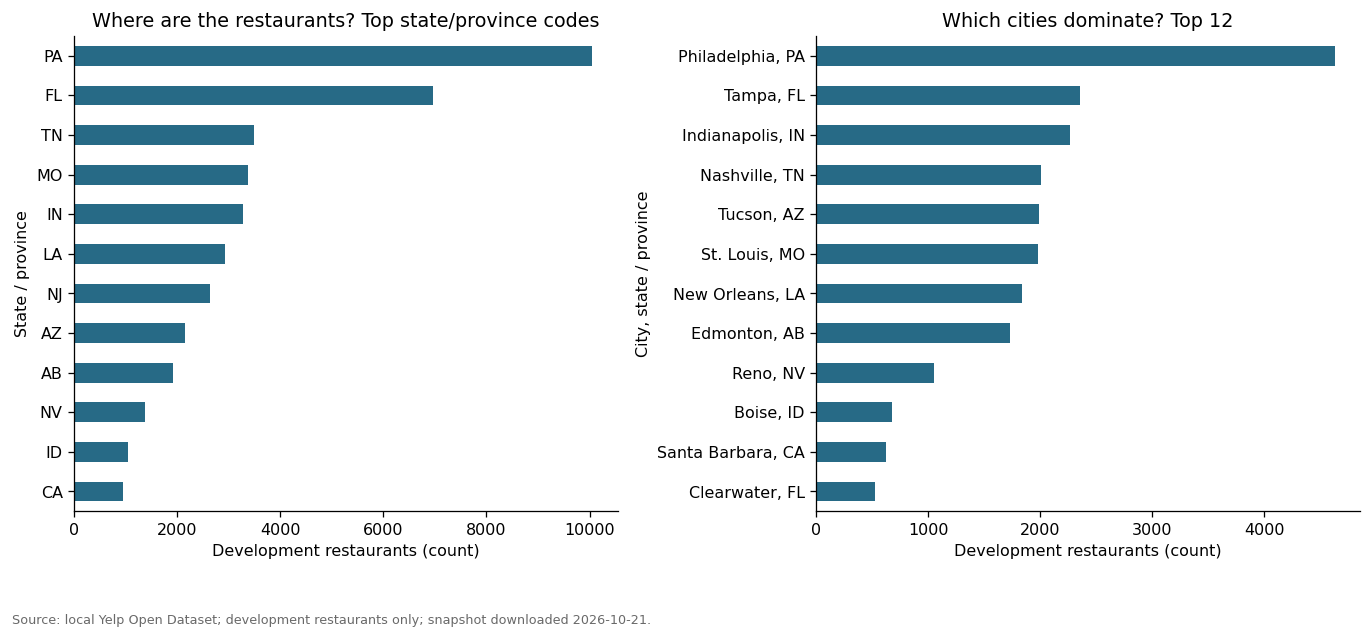

Takeaway: 33 of the 50 US states have no restaurant records in this release. State summaries describe the included locations, not representative statewide populations; a random holdout will not demonstrate generalization to unobserved regions.

In [7]:
US_STATES = 'AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY'.split()
all_state_counts = restaurants.state.value_counts()
us_coverage = all_state_counts.reindex(US_STATES, fill_value=0).rename('restaurant_rows').to_frame()
zero_states = us_coverage.index[us_coverage.restaurant_rows.eq(0)].tolist()
print(f'{len(zero_states)} of 50 US states have zero restaurant rows:')
print(', '.join(zero_states))
print('US states with at least one row:')
display(us_coverage.query('restaurant_rows > 0').sort_values('restaurant_rows', ascending=False))
print('Codes outside the 50 US states (inspect separately):')
display(all_state_counts.loc[~all_state_counts.index.isin(US_STATES)].rename('restaurant_rows').to_frame())
print('A code outside the US list may be a Canadian province (AB) or an anomalous code (XMS); do not infer a country from this test alone.')
print('Regions with fewer than 30 restaurant rows, retained but unsuitable for regional comparisons:')
display(all_state_counts[all_state_counts < 30].rename('restaurant_rows').to_frame())
us_coverage.to_csv(OUT / 'us_state_coverage.csv', index_label='state')

state_counts = dev.state.value_counts()
city_counts = dev.city_state.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
state_counts.head(12).sort_values().plot.barh(ax=axes[0], color=BLUE)
city_counts.head(12).sort_values().plot.barh(ax=axes[1], color=BLUE)
axes[0].set(title='Where are the restaurants? Top state/province codes', xlabel='Development restaurants (count)', ylabel='State / province')
axes[1].set(title='Which cities dominate? Top 12', xlabel='Development restaurants (count)', ylabel='City, state / province')
finish(fig, '02_geographic_coverage.png')
takeaway(f'{len(zero_states)} of the 50 US states have no restaurant records in this release. '
         'State summaries describe the included locations, not representative statewide populations; a random holdout will not demonstrate generalization to unobserved regions.')

6. Explore ratings and reviews

Compare business ratings and review counts. Ratings based on fewer reviews may be less stable.

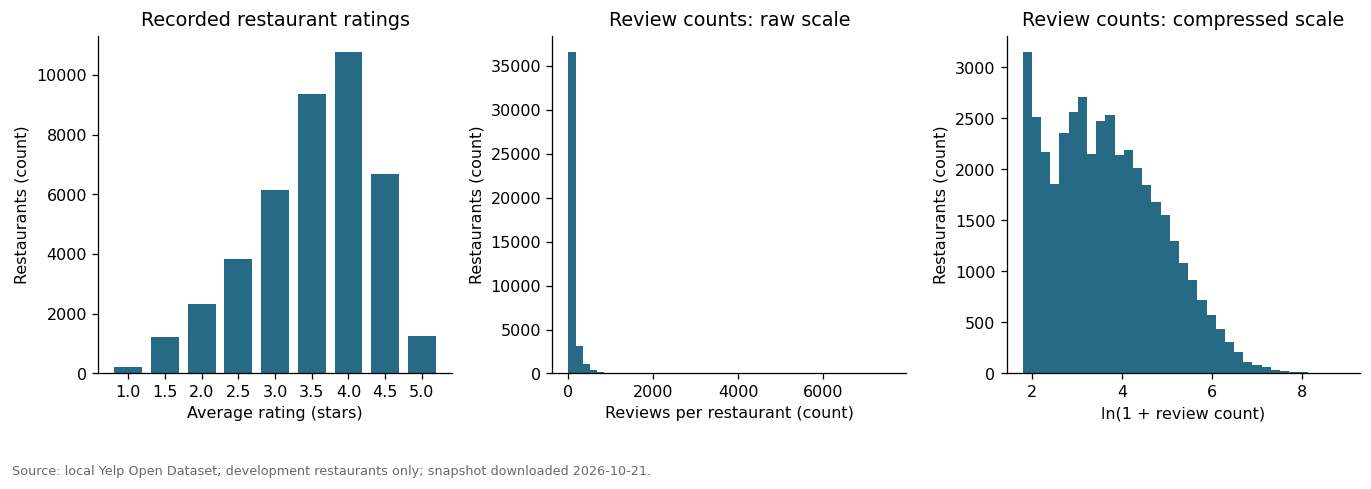

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
stars,41802.0,3.51,0.83,1.0,2.0,3.0,3.5,4.0,4.5,5.0,5.0
review_count,41802.0,87.80,193.11,5.0,6.0,13.0,33.0,89.0,333.0,759.0,7568.0


Takeaway: The development mean rating is 3.51 stars and the median is 3.5. The median restaurant has 33 reviews, and 35.0% have fewer than 20. These describe observed ratings; they do not measure future prediction accuracy.

In [8]:
rating_counts = dev.stars.value_counts().reindex(np.arange(1, 5.01, 0.5), fill_value=0).sort_index()
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
axes[0].bar(rating_counts.index, rating_counts.values, width=.38, color=BLUE)
axes[0].set(title='Recorded restaurant ratings', xlabel='Average rating (stars)', ylabel='Restaurants (count)', xticks=np.arange(1, 5.1, .5))
axes[1].hist(dev.review_count, bins=45, color=BLUE)
axes[1].set(title='Review counts: raw scale', xlabel='Reviews per restaurant (count)', ylabel='Restaurants (count)')
axes[2].hist(dev.log1p_review_count, bins=35, color=BLUE)
axes[2].set(title='Review counts: compressed scale', xlabel='ln(1 + review count)', ylabel='Restaurants (count)')
finish(fig, '03_ratings_and_review_counts.png')
display(dev[['stars', 'review_count']].describe(percentiles=[.05, .25, .5, .75, .95, .99]).T.round(2))
low_count_fraction = float(dev.review_count.lt(20).mean())
takeaway(f'The development mean rating is {dev.stars.mean():.2f} stars and the median is {dev.stars.median():.1f}. '
         f'The median restaurant has {dev.review_count.median():.0f} reviews, and {low_count_fraction:.1%} have fewer than 20. '
         'These describe observed ratings; they do not measure future prediction accuracy.')

,size,mean,median,std
review_count_band,,,,
0–19,14614,3.340,3.5,0.951
20–49,10766,3.414,3.5,0.846
50–99,6972,3.618,3.5,0.712
100–249,6235,3.771,4.0,0.591
250+,3215,3.922,4.0,0.467


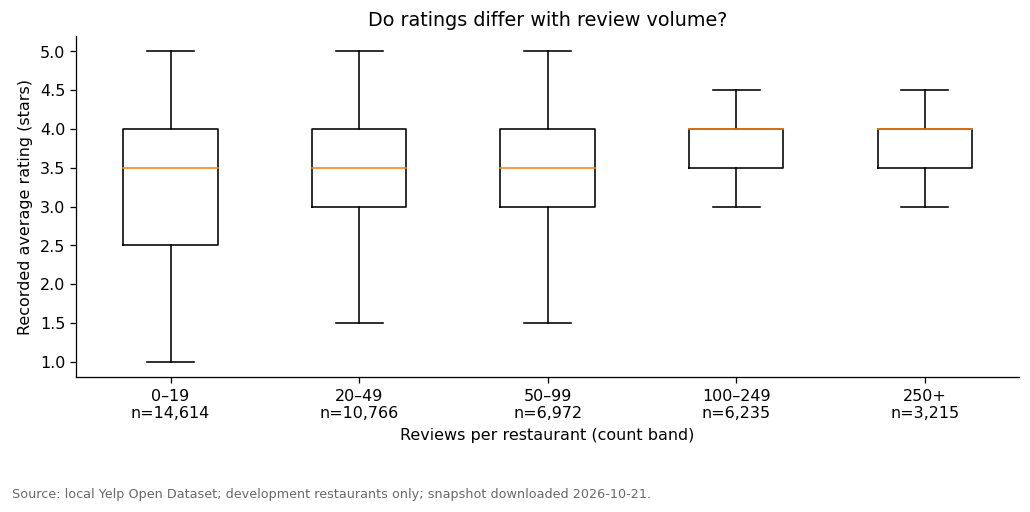

Takeaway: Review volume describes how much rating evidence a restaurant has, but it is accumulated after opening. Use it only if the eventual prediction scenario makes it available; it is excluded from the core attribute-only predictor list below. Differences between count bands cannot establish that more reviews cause better or more reliable ratings.

In [9]:
dev['review_count_band'] = pd.cut(dev.review_count, bins=[-1, 19, 49, 99, 249, np.inf],
                                 labels=['0–19', '20–49', '50–99', '100–249', '250+'])
count_band_summary = dev.groupby('review_count_band', observed=True).stars.agg(['size', 'mean', 'median', 'std'])
display(count_band_summary.round(3))
fig, ax = plt.subplots(figsize=(9, 4.4))
labels = list(count_band_summary.index.astype(str))
groups = [dev.loc[dev.review_count_band.astype(str).eq(label), 'stars'].to_numpy() for label in labels]
ax.boxplot(groups, labels=[f'{label}\nn={len(values):,}' for label, values in zip(labels, groups)], showfliers=False)
ax.set(title='Do ratings differ with review volume?', xlabel='Reviews per restaurant (count band)', ylabel='Recorded average rating (stars)', ylim=(.8, 5.2))
finish(fig, '04_rating_by_review_volume.png')
takeaway('Review volume describes how much rating evidence a restaurant has, but it is accumulated after opening. '
         'Use it only if the eventual prediction scenario makes it available; it is excluded from the core attribute-only predictor list below. '
         'Differences between count bands cannot establish that more reviews cause better or more reliable ratings.')

7. Compare business attributes

Compare ratings by price and amenities, keeping Unknown separate. Differences do not establish cause and effect.

,size,mean,median,std
price_group,,,,
1,15593,3.298,3.5,0.932
2,18494,3.587,3.5,0.677
3,1331,3.683,4.0,0.617
4,149,3.644,4.0,0.800
Unknown,6235,3.802,4.0,0.887


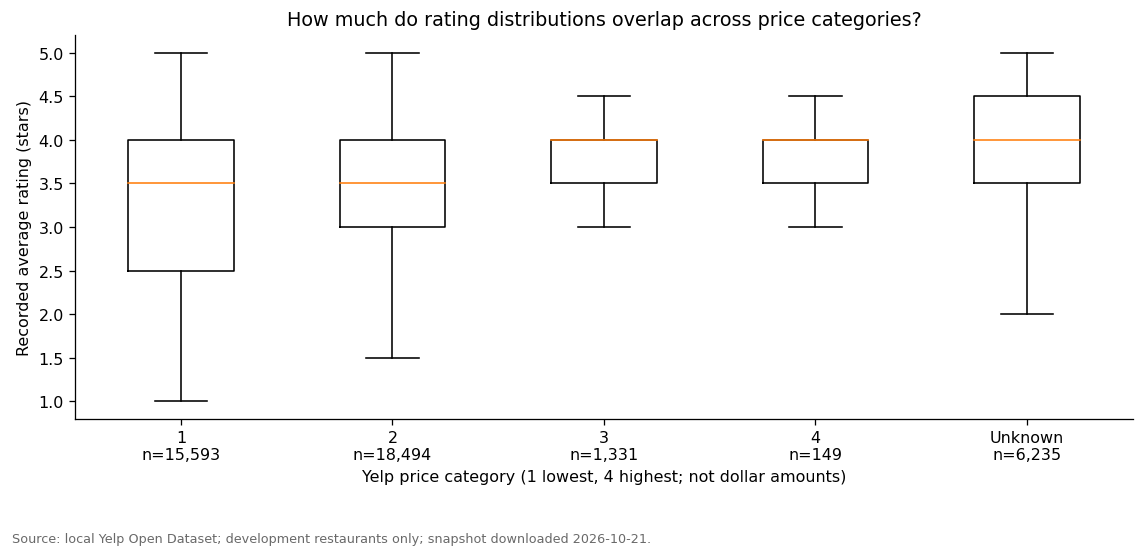

,attribute,group,n,mean_stars
0,takeout,No,1820,3.320
1,takeout,Yes,36269,3.509
2,takeout,Unknown,3713,3.664
3,delivery,No,14047,3.611
4,delivery,Yes,21982,3.402
5,delivery,Unknown,5773,3.711
6,outdoor_seating,No,17583,3.391
7,outdoor_seating,Yes,15938,3.647
8,outdoor_seating,Unknown,8281,3.522
9,reservations,No,22788,3.403


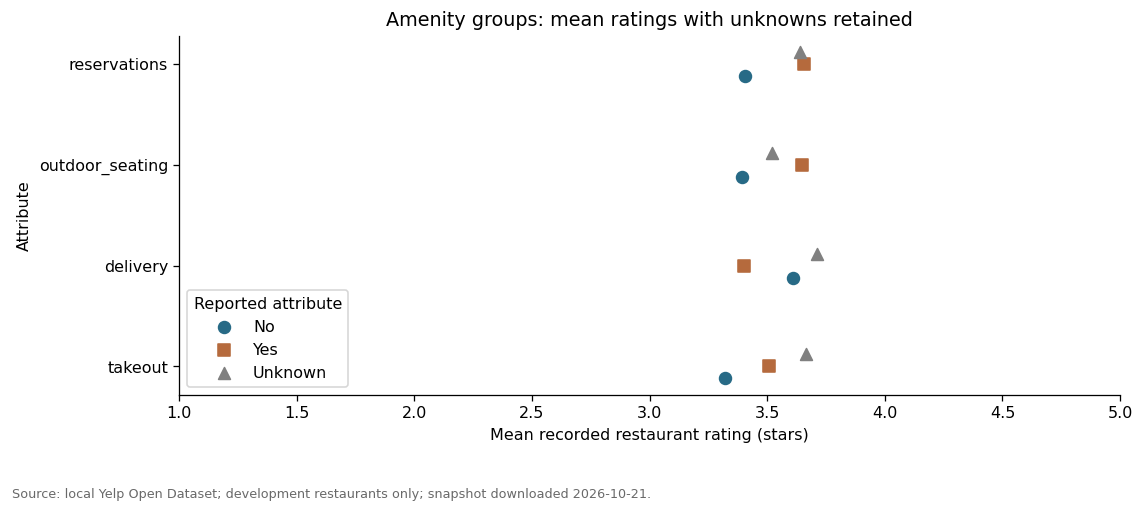

Takeaway: Price categories 1 and 2 average 3.30 and 3.59 stars, respectively, but their distributions overlap. The Unknown price group averages 3.80 stars, so discarding missing price rows can change the observed restaurant mix. These are descriptive associations, not evidence that increasing prices causes higher ratings.

In [10]:
price_order = ['1', '2', '3', '4', 'Unknown']
price_values = dev.price_range.fillna('Unknown')
price_summary = dev.assign(price_group=price_values).groupby('price_group').stars.agg(['size', 'mean', 'median', 'std']).reindex(price_order)
display(price_summary.round(3))
fig, ax = plt.subplots(figsize=(10, 4.8))
price_groups = [dev.loc[price_values.eq(label), 'stars'].to_numpy() for label in price_order]
ax.boxplot(price_groups, labels=[f'{label}\nn={len(values):,}' for label, values in zip(price_order, price_groups)], showfliers=False)
ax.set(title='How much do rating distributions overlap across price categories?',
       xlabel='Yelp price category (1 lowest, 4 highest; not dollar amounts)',
       ylabel='Recorded average rating (stars)', ylim=(.8, 5.2))
finish(fig, '05_rating_by_price.png')

amenity_rows = []
for attribute in binary_attributes:
    table = dev.assign(group=dev[attribute].fillna('Unknown')).groupby('group').stars.agg(['size', 'mean', 'std'])
    for group in ['No', 'Yes', 'Unknown']:
        if group in table.index:
            amenity_rows.append({'attribute': attribute, 'group': group, 'n': int(table.loc[group, 'size']), 'mean_stars': float(table.loc[group, 'mean'])})
amenity_summary = pd.DataFrame(amenity_rows)
display(amenity_summary.round(3))
fig, ax = plt.subplots(figsize=(10, 4.4))
for offset, group, color, marker in [(-.12, 'No', BLUE, 'o'), (0, 'Yes', ORANGE, 's'), (.12, 'Unknown', 'gray', '^')]:
    values = amenity_summary.query('group == @group').set_index('attribute').reindex(binary_attributes)
    ax.scatter(values.mean_stars, np.arange(len(binary_attributes)) + offset, label=group, color=color, marker=marker, s=55)
ax.set(yticks=np.arange(len(binary_attributes)), yticklabels=binary_attributes, xlim=(1, 5),
       title='Amenity groups: mean ratings with unknowns retained', xlabel='Mean recorded restaurant rating (stars)', ylabel='Attribute')
ax.legend(title='Reported attribute', loc='lower left')
finish(fig, '06_amenity_associations.png')
takeaway(f'Price categories 1 and 2 average {price_summary.loc["1", "mean"]:.2f} and {price_summary.loc["2", "mean"]:.2f} stars, respectively, but their distributions overlap. '
         f'The Unknown price group averages {price_summary.loc["Unknown", "mean"]:.2f} stars, so discarding missing price rows can change the observed restaurant mix. '
         'These are descriptive associations, not evidence that increasing prices causes higher ratings.')

Compare delivery within cities

Compare Yes and No in the six largest development cities, with at least 30 businesses per group. Leave Unknown out of this comparison.

,city,No,Yes,n_no,n_yes,Yes_minus_No
0,"Philadelphia, PA",3.602,3.509,1270,2756,-0.093
1,"Tampa, FL",3.633,3.518,746,1212,-0.115
2,"Indianapolis, IN",3.611,3.335,724,1252,-0.276
3,"Nashville, TN",3.651,3.427,710,956,-0.223
4,"Tucson, AZ",3.523,3.345,651,1041,-0.178
5,"St. Louis, MO",3.654,3.417,800,881,-0.237


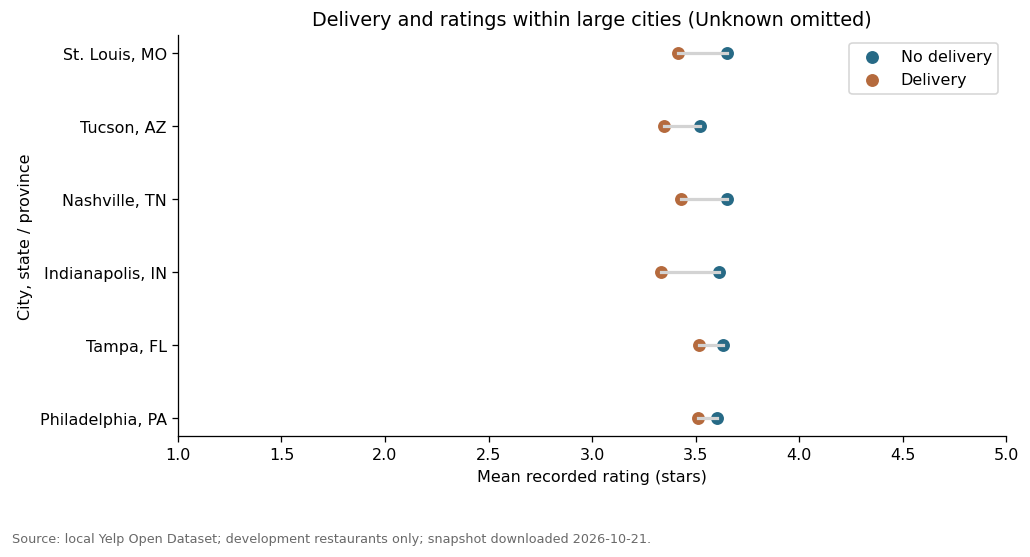

Takeaway: A pooled attribute difference can mix together restaurants from different markets. Within-city comparisons help reveal whether the relationship is consistent, but do not remove all confounding. These descriptive contrasts do not tell us what would happen if a restaurant changed its delivery policy.

In [11]:
delivery_cities = city_counts.head(6).index
delivery_by_city = (dev.loc[dev.city_state.isin(delivery_cities) & dev.delivery.isin(['Yes', 'No'])]
                   .groupby(['city_state', 'delivery']).stars.agg(['size', 'mean']))
city_delivery_rows = []
for city in delivery_cities:
    if city in delivery_by_city.index.get_level_values(0):
        groups = delivery_by_city.loc[city]
        if {'Yes', 'No'}.issubset(groups.index) and groups.loc[['Yes', 'No'], 'size'].min() >= 30:
            city_delivery_rows.append({'city': city, 'No': groups.loc['No', 'mean'], 'Yes': groups.loc['Yes', 'mean'],
                                       'n_no': int(groups.loc['No', 'size']), 'n_yes': int(groups.loc['Yes', 'size'])})
delivery_city_summary = pd.DataFrame(city_delivery_rows)
assert len(delivery_city_summary) > 0
delivery_city_summary['Yes_minus_No'] = delivery_city_summary.Yes - delivery_city_summary.No
display(delivery_city_summary.round(3))
fig, ax = plt.subplots(figsize=(9, 4.8))
for index, row in delivery_city_summary.iterrows():
    ax.plot([row['No'], row['Yes']], [index, index], color='lightgray', linewidth=2)
ax.scatter(delivery_city_summary['No'], np.arange(len(delivery_city_summary)), color=BLUE, label='No delivery', s=50)
ax.scatter(delivery_city_summary['Yes'], np.arange(len(delivery_city_summary)), color=ORANGE, label='Delivery', s=50)
ax.set(yticks=np.arange(len(delivery_city_summary)), yticklabels=delivery_city_summary.city, xlim=(1, 5),
       title='Delivery and ratings within large cities (Unknown omitted)', xlabel='Mean recorded rating (stars)', ylabel='City, state / province')
ax.legend()
finish(fig, '07_delivery_within_cities.png')
takeaway('A pooled attribute difference can mix together restaurants from different markets. '
         'Within-city comparisons help reveal whether the relationship is consistent, but do not remove all confounding. '
         'These descriptive contrasts do not tell us what would happen if a restaurant changed its delivery policy.')

8. Compare numeric features

Inspect correlations, distributions, and unusual values. Correlation alone does not show predictive accuracy.

,stars,review_count,latitude,longitude,category_count,listed_days,weekly_listed_hours
stars,1.000,0.203,-0.038,-0.003,0.105,-0.333,-0.431
review_count,0.203,1.000,-0.104,-0.044,0.215,0.014,-0.129
latitude,-0.038,-0.104,1.000,0.255,-0.061,0.009,0.007
longitude,-0.003,-0.044,0.255,1.000,-0.021,0.011,0.035
category_count,0.105,0.215,-0.061,-0.021,1.000,0.012,0.042
listed_days,-0.333,0.014,0.009,0.011,0.012,1.000,0.659
weekly_listed_hours,-0.431,-0.129,0.007,0.035,0.042,0.659,1.000


,stars,review_count,latitude,longitude,category_count,listed_days,weekly_listed_hours
stars,41802,41802,41802,41802,41802,35994,28267
review_count,41802,41802,41802,41802,41802,35994,28267
latitude,41802,41802,41802,41802,41802,35994,28267
longitude,41802,41802,41802,41802,41802,35994,28267
category_count,41802,41802,41802,41802,41802,35994,28267
listed_days,35994,35994,35994,35994,35994,35994,28267
weekly_listed_hours,28267,28267,28267,28267,28267,28267,28267


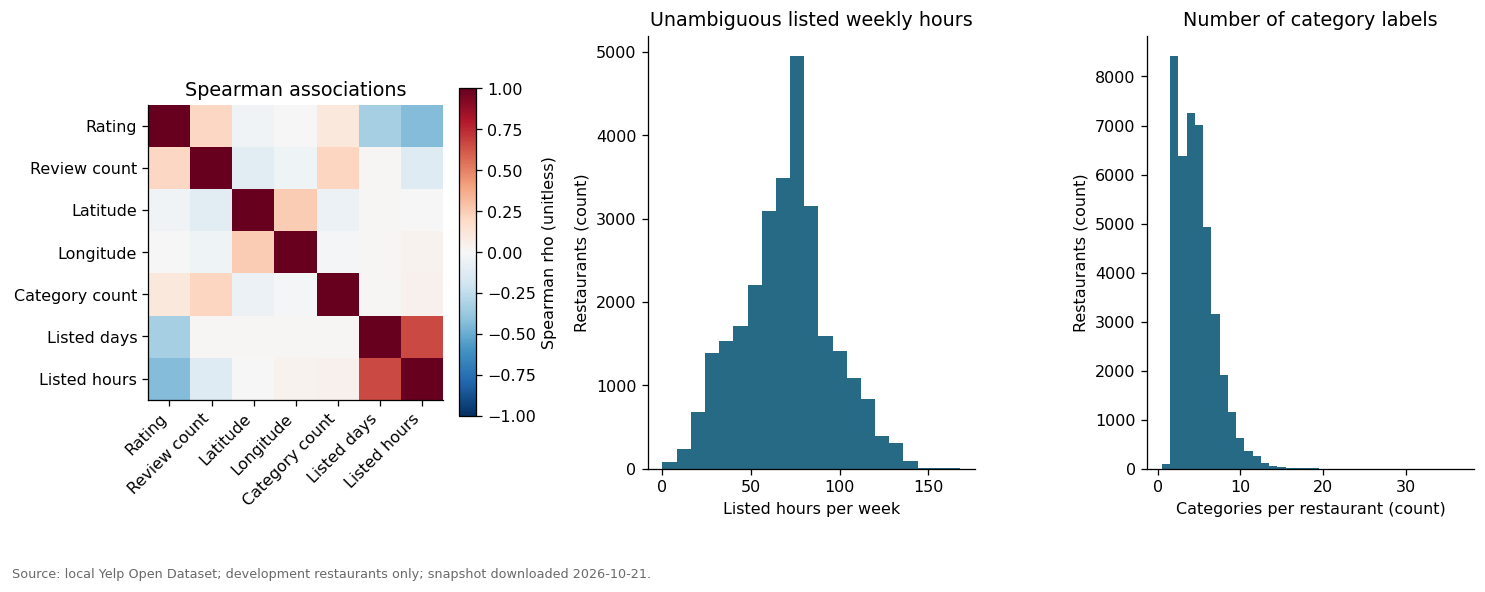

,0.00,0.01,0.50,0.99,1.00
review_count,5.00,5.0,33.0,759.0,7568.00
category_count,1.00,2.0,4.0,12.0,36.00
weekly_listed_hours,0.25,15.0,71.0,133.0,167.88


Takeaway: Numeric summaries help identify skew, unusual values, and possible redundant features. Large review counts are retained unless there is evidence of an error, and ambiguous schedules remain missing. Weak marginal correlations do not rule out interactions or nonlinear predictive relationships.

In [12]:
numeric_columns = ['stars', 'review_count', *numeric_features]
correlations = dev[numeric_columns].corr(method='spearman')
display(correlations.round(3))
display(dev[numeric_columns].notna().astype(int).T.dot(dev[numeric_columns].notna().astype(int)))
fig, axes = plt.subplots(1, 3, figsize=(13, 5.1))
heat = axes[0].imshow(correlations.to_numpy(), vmin=-1, vmax=1, cmap='RdBu_r')
short_labels = ['Rating', 'Review count', 'Latitude', 'Longitude', 'Category count', 'Listed days', 'Listed hours']
axes[0].set(xticks=range(len(numeric_columns)), yticks=range(len(numeric_columns)),
            xticklabels=short_labels, yticklabels=short_labels, title='Spearman associations')
plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')
fig.colorbar(heat, ax=axes[0], label='Spearman rho (unitless)', fraction=.05)
axes[1].hist(dev.weekly_listed_hours.dropna(), bins=np.arange(0, 169, 8), color=BLUE)
axes[1].set(title='Unambiguous listed weekly hours', xlabel='Listed hours per week', ylabel='Restaurants (count)')
axes[2].hist(dev.category_count, bins=np.arange(.5, dev.category_count.max() + 1.5), color=BLUE)
axes[2].set(title='Number of category labels', xlabel='Categories per restaurant (count)', ylabel='Restaurants (count)')
finish(fig, '08_numeric_relationships.png')
outlier_quantiles = dev[['review_count', 'category_count', 'weekly_listed_hours']].quantile([0, .01, .5, .99, 1]).T
display(outlier_quantiles.round(2))
takeaway('Numeric summaries help identify skew, unusual values, and possible redundant features. '
         'Large review counts are retained unless there is evidence of an error, and ambiguous schedules remain missing. '
         'Weak marginal correlations do not rule out interactions or nonlinear predictive relationships.')

9. Save the prepared data

Save separate development and holdout files for Restaurants, Food, and their union. Predict stars from business attributes; keep business_id for tracking only.

In [13]:
feature_spec = {'target': 'stars', 'id': 'business_id', 'split': 'split',
                'numeric_candidates': numeric_features, 'categorical_candidates': categorical_features,
                'excluded_from_core': ['review_count', 'log1p_review_count', 'is_open', 'postal_code', 'city',
                                       'hours_ambiguous', 'hours_malformed']}
for split in ['development', 'holdout']:
    frame = feature_frame.loc[feature_frame.split.eq(split)].copy()
    frame.to_csv(PROCESSED / f'restaurants_{split}.csv', index=False)
restaurants[['business_id', 'split']].to_csv(PROCESSED / 'restaurant_split.csv', index=False)
(OUT / 'feature_spec.json').write_text(json.dumps(feature_spec, indent=2))
missingness.to_csv(OUT / 'missingness.csv', index_label='variable')
price_summary.to_csv(OUT / 'rating_by_price.csv', index_label='price_range')
amenity_summary.to_csv(OUT / 'amenity_summary.csv', index=False)
delivery_city_summary.to_csv(OUT / 'delivery_by_city.csv', index=False)
correlations.to_csv(OUT / 'spearman_correlations.csv')
print('Saved development and holdout CSVs, split assignments, and summary files.')
print('Raw data unchanged. No predictive models fitted and no holdout performance calculated.')

# Separate candidate inputs; preserve the restaurant files used by notebook 02.
for population, selection in {
    'food': combined_features.is_food_tag,
    'restaurants_or_food': pd.Series(True, index=combined_features.index),
}.items():
    for partition in ['development', 'holdout']:
        candidate = combined_features.loc[selection & combined_features['split'].eq(partition)].copy()
        assert candidate.business_id.is_unique
        candidate.to_csv(PROCESSED / f'{population}_{partition}.csv', index=False)
combined_features[['business_id', 'split', 'is_restaurant_tag', 'is_food_tag', 'category_group']].to_csv(
    PROCESSED / 'restaurants_or_food_split.csv', index=False)
print('Also saved Food-tagged and Restaurants-or-Food candidate files; Food includes businesses with both tags.')


Saved development and holdout CSVs, split assignments, and summary files.
Raw data unchanged. No predictive models fitted and no holdout performance calculated.


Also saved Food-tagged and Restaurants-or-Food candidate files; Food includes businesses with both tags.


10. Review the findings

Summarize what the data suggests for modeling.

In [14]:
summary = {
    'question': 'Predict recorded restaurant-average stars from business attributes in the observed snapshot.',
    'source': 'Yelp Open Dataset downloaded 2026-10-21; business file only for this EDA.',
    'all_businesses': int(len(business)), 'all_restaurants': int(len(restaurants)),
    'development_restaurants': int(len(dev)), 'holdout_restaurants': int(len(holdout_ids)),
    'zero_us_states': zero_states,
    'sparse_regions': {str(k): int(v) for k, v in all_state_counts[all_state_counts < 30].items()},
    'all_state_counts': {str(k): int(v) for k, v in all_state_counts.items()},
    'mean_stars': float(dev.stars.mean()), 'median_stars': float(dev.stars.median()),
    'median_review_count': float(dev.review_count.median()), 'share_under_20_reviews': low_count_fraction,
    'ambiguous_hours_n': int(dev.hours_ambiguous.sum()),
    'city_label_changes': city_label_changes,
    'rating_distribution': [{'stars': float(k), 'restaurants': int(v)} for k, v in rating_counts.items()],
    'missingness': [{'field': str(k), 'pct': float(v)} for k, v in missingness.missing_pct.items()],
    'price_summary': [{'price': str(k), 'n': int(v['size']), 'mean': float(v['mean'])} for k, v in price_summary.iterrows()],
    'amenities': amenity_rows,
    'delivery_cities': delivery_city_summary.to_dict(orient='records'),
    'markets': {},
}
for market in ['All development', *state_counts[state_counts >= 100].index.tolist()]:
    subset = dev if market == 'All development' else dev.loc[dev.state.eq(market)]
    counts = subset.stars.value_counts().reindex(np.arange(1, 5.01, .5), fill_value=0).sort_index()
    summary['markets'][market] = {'n': int(len(subset)), 'mean': float(subset.stars.mean()),
        'ratings': [int(x) for x in counts.values],
        'price': [{'label': str(k), 'n': int(v['size']), 'mean': float(v['mean'])}
                  for k, v in subset.assign(price_group=subset.price_range.fillna('Unknown')).groupby('price_group').stars.agg(['size', 'mean']).iterrows()]}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False))
takeaway(f'We identified {len(restaurants):,} restaurants and reserved {len(holdout_ids):,} for later evaluation. '
         f'On {len(dev):,} development restaurants, the mean recorded rating is {dev.stars.mean():.2f} stars; '
         f'{low_count_fraction:.1%} have fewer than 20 reviews. '
         f'Coverage is geographically restricted: {len(zero_states)} US states have no restaurant rows, so these findings do not represent the nation.')

Takeaway: We identified 52,268 restaurants and reserved 10,466 for later evaluation. On 41,802 development restaurants, the mean recorded rating is 3.51 stars; 35.0% have fewer than 20 reviews. Coverage is geographically restricted: 33 US states have no restaurant rows, so these findings do not represent the nation.

Missing information, limited geography, and different business types affect interpretation.

Notebook 02 contains restaurant model results. It has already evaluated the restaurant holdout; Food and combined models remain untested.

Data sources and AI assistance are documented in data/source_manifest.json and AI_USAGE.md.